In [17]:
import numpy as np
from itertools import combinations
from time import perf_counter

In [18]:
# taken from https://gist.github.com/danoneata/49a807f47656fedbb389

def fvecs_read(filename, c_contiguous=True):
    """
    reads a file in the fvecs format, returning a 2D numpy array of shape (n, d)
    """
    fv = np.fromfile(filename, dtype=np.float32)
    if fv.size == 0:
        return np.zeros((0, 0))
    dim = fv.view(np.int32)[0]
    assert dim > 0
    fv = fv.reshape(-1, 1 + dim)
    if not all(fv.view(np.int32)[:, 0] == dim):
        raise IOError("Non-uniform vector sizes in " + filename)
    fv = fv[:, 1:]
    if c_contiguous:
        fv = fv.copy()
    return fv

In [19]:
# taken from https://gist.github.com/CharlesLiu7/0496773a8a21934a746e3fd496f11e0c

def ivecs_read(fname):
    a = np.fromfile(fname, dtype='int32')
    d = a[0]
    return a.reshape(-1, d + 1)[:, 1:].copy()

In [20]:
sim_hash_dimension = 64

def sim_hash(doc, m=sim_hash_dimension, d=128, seed=42):
    np.random.seed(seed)
    R = np.random.randn(m, d).astype('float32') # posso farla 1 volta sola e poi riusarla per tutti i documenti
    sim_hashes = np.dot(doc, R.T) > 0
    return sim_hashes.astype('uint8') #! should be bits

In [21]:
docs = fvecs_read('siftsmall/siftsmall_base.fvecs')
print(sim_hash(docs[0]))
print(sim_hash(docs[1]))

[0 1 1 1 1 0 1 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 1 0 0 1 1 1 1 0 1 0 0 0 0 1 0
 0 0 1 1 0 0 1 0 0 0 1 0 0 0 0 1 0 0 1 1 0 1 0 1 0 1 0]
[0 0 1 1 1 0 1 1 1 1 1 1 0 0 1 1 0 0 1 0 0 1 1 0 0 1 0 1 1 0 0 1 0 0 0 1 0
 0 0 1 1 0 1 0 0 0 1 1 0 0 0 1 0 0 0 1 1 0 0 0 1 0 0 0]


In [57]:
def nn_distance(query, data, k=10):
    dist = np.count_nonzero(query != data) #! can be bitwise AND
    if dist <= k:
        return dist
    else:
        return None
    # if dist < k:
    #     return dist

In [66]:
start = perf_counter()
hashes = [sim_hash(d) for d in docs]
end = perf_counter()
print(f"Time to compute simhashes: {end - start}")

def close_pairs_generator(hashes, k):
    close_pairs = []
    total_running_time = 0
    for i, j in combinations(range(len(hashes)), 2):
        start = perf_counter()
        result = nn_distance(hashes[i], hashes[j], k=k)
        total_running_time += perf_counter() - start
        if result is not None:
            close_pairs.append((i, j, result))
            # print(f"Distance between index {i} and {j}: {result}")
    
    return close_pairs, total_running_time

close_pairs, total_running_time = close_pairs_generator(hashes, k=2)
print(f"Total running time: {total_running_time}")
print(f"Average running time per pair: {total_running_time / len(close_pairs) if close_pairs else 0}")
print(f"Number of close pairs: {len(close_pairs)}")

Time to compute simhashes: 1.754376599972602
Total running time: 60.340383321396075
Average running time per pair: 0.03446052731090581
Number of close pairs: 1751


In [67]:
import matplotlib.pyplot as plt

k_values = [2, 4, 6, 8, 10, 15, 20]

num_close_pairs = []
running_times = []
close_pairs = [] #! should be a list of lists, one for each k
for i in k_values:
    close_pairs_, total_running_time = close_pairs_generator(hashes, k=i)
    num_close_pairs.append(len(close_pairs_))
    running_times.append(total_running_time)
    close_pairs.append(close_pairs_)
    print(f"k={i}: Total running time: {total_running_time}, Average running time per pair: {total_running_time / len(close_pairs_) if close_pairs_ else 0}, Number of close pairs: {len(close_pairs_)}")

k=2: Total running time: 55.451307949610054, Average running time per pair: 0.03166836547664766, Number of close pairs: 1751
k=4: Total running time: 56.28605632495601, Average running time per pair: 0.004610587837889581, Number of close pairs: 12208
k=6: Total running time: 54.617103155876976, Average running time per pair: 0.0008518748347611595, Number of close pairs: 64114
k=8: Total running time: 59.391811285342555, Average running time per pair: 0.00022516856336807076, Number of close pairs: 263766
k=10: Total running time: 67.16122795199044, Average running time per pair: 7.83410432045875e-05, Number of close pairs: 857293
k=15: Total running time: 59.295325790008064, Average running time per pair: 9.427339498420926e-06, Number of close pairs: 6289720
k=20: Total running time: 60.69529754796531, Average running time per pair: 3.5694629281652744e-06, Number of close pairs: 17004042


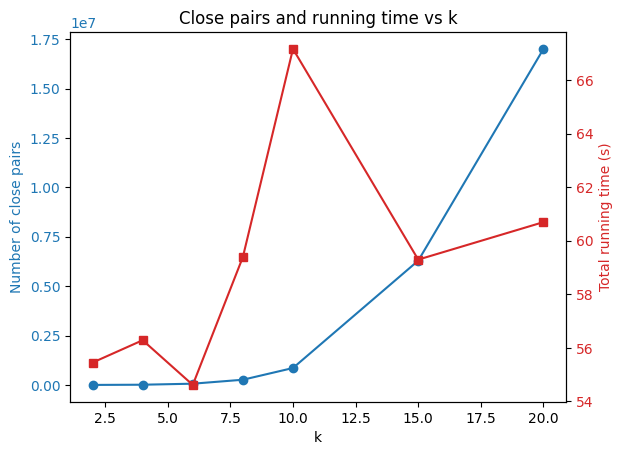

In [68]:
fig, ax1 = plt.subplots()

color = 'tab:blue'
ax1.set_xlabel('k')
ax1.set_ylabel('Number of close pairs', color=color)
ax1.plot(k_values, num_close_pairs, marker='o', color=color)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Total running time (s)', color=color)
ax2.plot(k_values, running_times, marker='s', color=color)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Close pairs and running time vs k')
plt.show()

## Bruteforce Near-Duplicate Detection with SimHash

just a baseline to confront with spark implementation

# banded approach

## spark sanity check

In [69]:
import os
import sys
from pyspark.sql import SparkSession
from pyspark.sql.functions import col

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

spark = (
    SparkSession.builder
    .appName("spark-smoke-test")
    .master("local[*]")
    .config("spark.pyspark.python", sys.executable)
    .config("spark.pyspark.driver.python", sys.executable)
    .getOrCreate()
)

print("Driver Python:", sys.executable)
print("Spark version:", spark.version)

# df = spark.createDataFrame([(1, "a"), (2, "b"), (3, "c")], ["id", "letter"])
# result = df.filter(col("id") > 1).orderBy("id").collect()

# print("Result:", result)
# assert [row.id for row in result] == [2, 3]
# assert [row.letter for row in result] == ["b", "c"]

print("Spark is working correctly.")

sc = spark.sparkContext


Driver Python: c:\Python311\python.exe
Spark version: 4.1.1
Spark is working correctly.


In [70]:
def divide_bands(hash, num_bands, doc_id):
    band_size = len(hash) // num_bands
    h = [((hash[i * band_size:(i + 1) * band_size].tobytes(), i), (doc_id, hash.tobytes())) for i in range(num_bands)]
    return h

divide_bands(hashes[0], num_bands=4, doc_id=1)


[((b'\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01', 0),
  (1,
   b'\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x00\x01\x01\x01\x01\x00\x01\x00\x00\x00\x00\x01\x00\x00\x00\x01\x01\x00\x00\x01\x00\x00\x00\x01\x00\x00\x00\x00\x01\x00\x00\x01\x01\x00\x01\x00\x01\x00\x01\x00')),
 ((b'\x01\x01\x01\x00\x01\x01\x01\x00\x00\x01\x01\x01\x01\x00\x01\x00', 1),
  (1,
   b'\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x00\x01\x01\x01\x01\x00\x01\x00\x00\x00\x00\x01\x00\x00\x00\x01\x01\x00\x00\x01\x00\x00\x00\x01\x00\x00\x00\x00\x01\x00\x00\x01\x01\x00\x01\x00\x01\x00\x01\x00')),
 ((b'\x00\x00\x00\x01\x00\x00\x00\x01\x01\x00\x00\x01\x00\x00\x00\x01', 2),
  (1,
   b'\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x00\x01\x01\x01\x01\x00\x01\x00\x00\x00\x00\x01\x00\x00\x00\x01\x01\x00\x00\x01\x00\x00\x00\x01\x00\x00\x00\x00\x01\x00\

In [71]:
def nn_distance_spark(query, data, k=10):
    query = np.frombuffer(query, dtype=np.uint8)
    data = np.frombuffer(data, dtype=np.uint8)
    dist = np.count_nonzero(query != data) #! can be bitwise AND
    if dist <= k:
        return dist
    else:
        return None

In [72]:
# rdd = sc.parallelize(hashes) # fai map 
rdd = sc.parallelize(docs)
rdd.zipWithIndex()

candidates = (
    rdd.zipWithIndex()
    .map(lambda h: (sim_hash(h[0]), h[1])) # (simhash, doc_id)
    # .map(lambda h: (h[0].tobytes(), h[1],)) 
    .map(lambda h: divide_bands(h[0], num_bands=4, doc_id=h[1]))
    .flatMap(lambda x: x)
    .mapValues(lambda doc_id: [doc_id])
    .reduceByKey(lambda a, b: a + b)
)
# candidates.take(5)

candidate_pairs = (
    candidates
    .flatMap(lambda kv: [tuple(sorted(pair)) for pair in combinations(kv[1], 2)])  # list of (id1,id2)
    .map(lambda pair: (pair, None))
    .distinct()
    .map(lambda x: x[0])                   # (id1, id2)
    # .filter(lambda pair: nn_distance_spark(pair[0][1], pair[1][1], k=20) is not None) #! to uncomment to have the final result without collecting all pairs
)

pairs = candidate_pairs.collect()

print(len(pairs))

# pairs = candidate_pairs.collect()
# # docid + simhash completo invece di broadcast
# results = []
# for i, j in pairs:
#     dist = nn_distance(hashes[i - 1], hashes[j - 1], k=2)
#     if dist is not None:
#         results.append(((i, j), dist))

# results = []
# for (i, hi), (j, hj) in pairs:
#     dist = nn_distance_spark(hi, hj, k=2)
#     if dist is not None:
#         results.append(((i, j), dist))

# print(len(results))

628437


In [54]:
results = []
for (i, hi), (j, hj) in pairs:
    dist = nn_distance_spark(hi, hj, k=32)
    if dist is not None:
        results.append(((i, j), dist))

print(len(results))

628437


In [56]:
bf_pairs = {tuple(sorted((i, j))) for i, j, _ in close_pairs}
lsh_pairs = {tuple(sorted((i, j))) for (i, _), (j, _) in pairs}

only_bruteforce = bf_pairs - lsh_pairs
only_lsh = lsh_pairs - bf_pairs
common = bf_pairs & lsh_pairs

print("Brute force ma non LSH:", len(only_bruteforce))
print("LSH ma non brute force:", len(only_lsh))
print("In comune:", len(common))

print("Esempi brute force ma non LSH:", list(only_bruteforce)[:10])
print("Esempi LSH ma non brute force:", list(only_lsh)[:10])
print("Esempi in comune:", list(common))

Brute force ma non LSH: 0
LSH ma non brute force: 628423
In comune: 14
Esempi brute force ma non LSH: []
Esempi LSH ma non brute force: [(1159, 3518), (1035, 1762), (902, 8588), (181, 5822), (2057, 8051), (3979, 9524), (6415, 6492), (2117, 8856), (5379, 5408), (1581, 5089)]
Esempi in comune: [(46, 6009), (48, 7841), (48, 6160), (46, 5507), (21, 4259), (46, 2021), (8, 20), (46, 2497), (46, 5479), (46, 5148), (44, 6970), (36, 2336), (36, 1905), (10, 18)]


In [ ]:
# print(results)
# print(len(results))

[((5991, 6293), 1), ((7391, 7957), 0), ((4605, 5087), 1), ((479, 1029), 1), ((1632, 2024), 1), ((3379, 3777), 1), ((9825, 9843), 1), ((3458, 3902), 0), ((2022, 6010), 1), ((6458, 6678), 1), ((6507, 6657), 1), ((6480, 6688), 1), ((7454, 7922), 1), ((436, 988), 1), ((9595, 9713), 0), ((8500, 8972), 1), ((2071, 2917), 1), ((6805, 7487), 1), ((7829, 8271), 1), ((4920, 9888), 0), ((5173, 5335), 1), ((4561, 4739), 1), ((2446, 3154), 1), ((1025, 2224), 1), ((560, 8371), 1), ((1891, 2482), 1), ((7391, 8966), 1), ((9193, 9472), 1), ((5176, 5587), 1), ((4864, 4875), 1), ((8098, 9101), 1), ((4461, 4492), 0), ((4543, 4638), 0), ((113, 168), 1), ((873, 904), 1), ((464, 531), 0), ((440, 859), 1), ((2483, 3818), 1), ((6283, 8306), 1), ((2435, 3794), 1), ((9, 21), 1), ((5508, 6010), 1), ((1626, 1896), 1), ((7906, 8336), 0), ((2096, 2606), 0), ((37, 2337), 0), ((4640, 4726), 1), ((9548, 9618), 0), ((5359, 5931), 0), ((1289, 1781), 1), ((5811, 6407), 1), ((7124, 7850), 1), ((1925, 2297), 1), ((6911, 767

In [3]:
spark.stop()